# 📦 Sistem Pencarian Jalur Teroptimal dalam Jaringan Pengiriman Paket Menggunakan Graf Berbobot
### *(Studi Kasus: Optimasi Rute Kurir — CourierRoute)*

**Mata Kuliah:** Teori Graph dan Automata  
**Anggota Kelompok:**
1. **Rangga Akhdan A.S.P** — `2411102441111`
2. **M. Nabil Syafiq** — `2411102441110`
3. **Fatwa Ikhwan Maulaya** — `2411102441063`

**Topik Utama:** *Weighted Undirected Graph*, Representasi *Adjacency List* & *Adjacency Matrix*, Algoritma *Dijkstra* (*Single-Source Shortest Path*), serta Analisis Kompleksitas Waktu & Ruang.

---

## 1. Pendahuluan (Background & Rumusan Masalah)

### 1.1 Latar Belakang
Dalam industri logistik dan pengiriman paket (*last-mile courier delivery*), efisiensi pemilihan rute sangat menentukan biaya operasional bahan bakar, ketepatan waktu layanan (*Service Level Agreement*), dan kapasitas harian kurir. Jaringan jalan raya yang menghubungkan gudang pusat (*warehouse*) dengan berbagai titik pengantaran pelanggan memiliki jarak tempuh yang bervariasi dan saling bersilangan.

Masalah dunia nyata tersebut dapat direpresentasikan secara **diskrit** menggunakan **Teori Graf (*Graph Theory*)**:
- **Simpul (*Vertex* $V$)** merepresentasikan titik lokasi diskrit (Gudang Pusat `G` serta titik distribusi/pelanggan `A, B, C, D, E, F`).
- **Sisi (*Edge* $E$)** merepresentasikan ruas jalan raya yang menghubungkan dua lokasi secara langsung.
- **Bobot (*Weight* $w$)** merepresentasikan jarak fisik antar lokasi dalam satuan kilometer ($\text{km}$).

### 1.2 Rumusan Masalah
1. Bagaimana memodelkan jaringan lokasi pengiriman paket dan ruas jalan penghubungnya ke dalam struktur matematis graf berbobot tak berarah $G = (V, E, w)$ menggunakan *Adjacency List* dan *Adjacency Matrix*?
2. Bagaimana menerapkan **Algoritma Dijkstra** untuk menemukan jalur pengiriman paket teroptimal (total jarak tempuh minimum) dari lokasi awal ke lokasi tujuan?
3. Bagaimana menguji keandalan sistem pada skenario normal (*connected graph*) maupun kasus batas (*edge cases* seperti graf terputus, titik awal sama dengan tujuan, jalur alternatif berbobot sama, dan input tidak valid), serta berapa kompleksitas waktu dan ruang algoritmanya?

### 1.3 Tujuan & Batasan Masalah
- **Tujuan Proyek:** Membangun sistem simulasi dan pencarian jalur pengiriman paket teroptimal berbasis Python (`.ipynb`) yang terintegrasi dengan prototipe visual `CourierRoute.html`, lengkap dengan pembuktian langkah-demi-langkah (*trace*), pengujian *edge cases*, dan analisis kompleksitas Big-O.
- **Batasan Masalah:**
  1. Topologi utama menggunakan **7 simpul lokasi** (`G, A, B, C, D, E, F`) dan **9 ruas jalan berbobot**.
  2. Graf bersifat **tak berarah (*undirected*)** dan **berbobot non-negatif ($w(e) \ge 0$)** dalam satuan kilometer ($\text{km}$).
  3. Fokus optimasi adalah pencarian jalur terpendek satu pasangan asal–tujuan (*Single-Pair / Single-Source Shortest Path*), bukan kunjungan multi-pelanggan sekaligus (*Traveling Salesperson Problem*).

---
## 2. Dasar Teori (Theoretical Foundation)

### 2.1 Definisi Formal Graf Berbobot
Secara matematis, jaringan pengiriman paket dimodelkan sebagai pasangan terurut tiga komponen:
$$G = (V, E, w)$$
di mana:
1. $V = \{G, A, B, C, D, E, F\}$ adalah himpunan berhingga tak kosong dari **simpul (*vertices*)** dengan kardinalitas $|V| = 7$.
2. $E \subseteq \{\{u, v\} \mid u, v \in V,\, u \neq v\}$ adalah himpunan **sisi tak berarah (*undirected edges*)** dengan kardinalitas $|E| = 9$.
3. $w : E \to \mathbb{R}^+$ adalah **fungsi bobot non-negatif** yang memetakan setiap ruas jalan $e = \{u, v\} \in E$ ke jarak tempuh $w(u, v) > 0$ (dalam $\text{km}$).

### 2.2 Karakteristik Graf pada Sistem CourierRoute
| Karakteristik | Pilihan Model Sistem | Alasan Teknis & Matematis |
| :--- | :--- | :--- |
| **Arah Sisi** | **Tak Berarah (*Undirected Graph*)** | Setiap ruas jalan diasumsikan dua arah simetris: jika kurir dapat bergerak dari $u$ ke $v$ sejauh $w\text{ km}$, maka kurir juga dapat bergerak dari $v$ ke $u$ sejauh $w\text{ km}$ ($w(u,v) = w(v,u)$). |
| **Bobot Sisi** | **Berbobot (*Weighted Graph*)** | Jarak antar lokasi tidak seragam (antara $2\text{ km}$ hingga $7\text{ km}$). Jalur dengan jumlah belokan/simpul paling sedikit **belum tentu** merupakan jalur terpendek. |
| **Sifat Bobot** | **Non-Negatif ($w(e) \ge 0$)** | Jarak fisik di dunia nyata tidak mungkin bernilai negatif, sehingga memenuhi syarat mutlak keoptimalan algoritma *greedy* Dijkstra. |

### 2.3 Prinsip Relaksasi (*Edge Relaxation*) pada Algoritma Dijkstra
Algoritma Dijkstra menyimpan estimasi jarak terpendek sementara $d[v]$ dari titik awal $s$ ke setiap simpul $v \in V$. Pada awalnya, $d[s] = 0$ dan $d[v] = \infty$ untuk $v \neq s$. Setiap kali simpul $u$ dengan jarak terkecil yang belum dikunjungi dipilih, dilakukan uji **Relaksasi (*Relaxation*)** terhadap seluruh tetangganya $v$:

$$\text{Jika } d[u] + w(u, v) < d[v], \quad \text{maka perbarui } d[v] \leftarrow d[u] + w(u, v) \text{ dan } \text{prev}[v] \leftarrow u$$

In [1]:
from typing import Dict, List, Tuple, Optional
import math
import heapq

# 1. Definisi Simpul (Vertices) beserta Koordinat Visualisasi (sesuai CourierRoute.html)
NODES: Dict[str, Dict[str, object]] = {
    "G": {"name": "Gudang Pusat", "x": 100, "y": 235},
    "A": {"name": "Lokasi A",     "x": 280, "y": 105},
    "B": {"name": "Lokasi B",     "x": 280, "y": 350},
    "C": {"name": "Lokasi C",     "x": 480, "y": 65},
    "D": {"name": "Lokasi D",     "x": 480, "y": 235},
    "E": {"name": "Lokasi E",     "x": 480, "y": 390},
    "F": {"name": "Lokasi F",     "x": 670, "y": 235},
}

# 2. Definisi Sisi Berbobot (Weighted Undirected Edges) dalam satuan kilometer (km)
INITIAL_EDGES: List[Tuple[str, str, float]] = [
    ("G", "A", 5.0),
    ("G", "B", 4.0),
    ("A", "C", 3.0),
    ("A", "D", 6.0),
    ("B", "D", 7.0),
    ("B", "E", 2.0),
    ("C", "F", 5.0),
    ("D", "F", 2.0),
    ("E", "F", 6.0),
]

def build_adjacency_list(
    nodes: List[str], edges: List[Tuple[str, str, float]]
) -> Dict[str, List[Tuple[str, float]]]:
    """Membangun representasi Adjacency List untuk graf tak berarah berbobot."""
    adj: Dict[str, List[Tuple[str, float]]] = {u: [] for u in nodes}
    for u, v, w in edges:
        if w < 0:
            raise ValueError(f"Bobot negatif tidak diizinkan pada Dijkstra: ({u}, {v}, {w})")
        adj[u].append((v, float(w)))
        adj[v].append((u, float(w)))
    return adj

def build_adjacency_matrix(
    nodes: List[str], edges: List[Tuple[str, str, float]]
) -> List[List[float]]:
    """Membangun representasi Adjacency Matrix (Matriks Ketetanggaan) berukuran |V| x |V|."""
    idx = {node: i for i, node in enumerate(nodes)}
    n = len(nodes)
    matrix = [[0.0 if i == j else math.inf for j in range(n)] for i in range(n)]
    for u, v, w in edges:
        i, j = idx[u], idx[v]
        matrix[i][j] = float(w)
        matrix[j][i] = float(w)
    return matrix

# Bangun kedua representasi data
node_list = list(NODES.keys())
adj_list = build_adjacency_list(node_list, INITIAL_EDGES)
adj_matrix = build_adjacency_matrix(node_list, INITIAL_EDGES)

print("=" * 72)
print("1. REPRESENTASI ADJACENCY LIST (DAFTAR KETETANGGAAN) & DERAJAT SIMPUL")
print("=" * 72)
print(f"{'Simpul':<8} | {'Nama Lokasi':<15} | {'Derajat deg(v)':<14} | {'Tetangga (Lokasi: Jarak)'}")
print("-" * 72)
for u in node_list:
    neighbors_str = ", ".join([f"{v} ({w:.0f} km)" for v, w in adj_list[u]])
    print(f"  {u:<6} | {NODES[u]['name']:<15} | {len(adj_list[u]):^14} | {neighbors_str}")

print("\n" + "=" * 72)
print("2. REPRESENTASI ADJACENCY MATRIX (MATRIKS KETETANGGAAN 7x7 dalam km)")
print("=" * 72)
header = "Dari / Ke | " + " | ".join([f"{n:^5}" for n in node_list])
print(header)
print("-" * len(header))
for i, u in enumerate(node_list):
    row_str = " | ".join([f"{'∞':^5}" if math.isinf(val) else f"{val:^5.0f}" for val in adj_matrix[i]])
    print(f"   {u:<6} | {row_str}")

1. REPRESENTASI ADJACENCY LIST (DAFTAR KETETANGGAAN) & DERAJAT SIMPUL
Simpul   | Nama Lokasi     | Derajat deg(v) | Tetangga (Lokasi: Jarak)
------------------------------------------------------------------------
  G      | Gudang Pusat    |       2        | A (5 km), B (4 km)
  A      | Lokasi A        |       3        | G (5 km), C (3 km), D (6 km)
  B      | Lokasi B        |       3        | G (4 km), D (7 km), E (2 km)
  C      | Lokasi C        |       2        | A (3 km), F (5 km)
  D      | Lokasi D        |       3        | A (6 km), B (7 km), F (2 km)
  E      | Lokasi E        |       2        | B (2 km), F (6 km)
  F      | Lokasi F        |       3        | C (5 km), D (2 km), E (6 km)

2. REPRESENTASI ADJACENCY MATRIX (MATRIKS KETETANGGAAN 7x7 dalam km)
Dari / Ke |   G   |   A   |   B   |   C   |   D   |   E   |   F  
-----------------------------------------------------------------
   G      |   0   |   5   |   4   |   ∞   |   ∞   |   ∞   |   ∞  
   A      |   5   |   0

---
## 3. Perancangan & Implementasi: Pseudocode Ramah Presentasi

Agar mudah dipahami saat presentasi, cara kerja **Algoritma Dijkstra** dapat dianalogikan seperti **seorang kurir yang membawa buku catatan jarak terpendek**:
1. **Tahap 1 (Persiapan Buku Catatan):** Tulis jarak `0 km` untuk lokasi awal (Gudang `G`), dan tulis `∞` (belum tahu) untuk semua lokasi lain. Masukkan lokasi awal ke dalam antrean prioritas (*Min-Heap*).
2. **Tahap 2 (Kunjungi Lokasi Terdekat):** Ambil lokasi di antrean yang punya catatan jarak paling kecil dan belum pernah dikunci (*final*).
3. **Tahap 3 (Cek Jalan ke Tetangga / *Relaxation*):** Dari lokasi tersebut, lihat semua jalan ke tetangganya. Hitung: *"Apakah lewat jalan ini lebih dekat daripada catatan lama di buku?"* Jika **lebih dekat**, coret catatan lama, tulis jarak baru yang lebih hemat, dan catat kita datang dari simpul mana.
4. **Tahap 4 (Susun Rute Mundur / *Backtracking*):** Setelah sampai di tujuan, runut balik catatan *"datang dari mana"* (`prev`) dari tujuan kembali ke titik awal.

### Pseudocode Terstruktur (4 Tahap Presentasi)

```text
ALGORITMA DIJKSTRA_JALUR_TEROPTIMAL(Graf, Awal, Tujuan)
-------------------------------------------------------------------------
// TAHAP 1: INISIALISASI (Siapkan tabel jarak & jejak rute)
1. Untuk setiap simpul v di dalam Graf:
       jarak[v] ← ∞                  // Awalnya semua lokasi dianggap sangat jauh
       induk[v] ← KOSONG             // Penanda simpul sebelumnya untuk merunut rute
2. jarak[Awal] ← 0                   // Jarak dari titik awal ke dirinya sendiri = 0 km
3. AntreanPrioritas ← [(0, Awal)]    // Min-Heap berisi pasangan (total_jarak, simpul)
4. Dikunjungi ← HimpunanKosong()     // Menyimpan simpul yang jaraknya sudah pasti minimal

// TAHAP 2: EKSPLORASI SIMPUL TERDEKAT (Greedy Selection)
5. Selama AntreanPrioritas tidak kosong:
       (jarak_sekarang, u) ← Ambil_Jarak_Terkecil(AntreanPrioritas)

       Jika u sudah ada di Dikunjungi:
           Lanjutkan ke iterasi berikutnya (abaikan duplikat lama di antrean)
       Tambahkan u ke Dikunjungi

       // Berhenti lebih awal (Early Exit) jika simpul Tujuan sudah dikunci!
       Jika u == Tujuan:
           Keluar dari perulangan (Jarak minimum ke Tujuan sudah pasti ditemukan)

       // TAHAP 3: RELAKSASI TETANGGA (Perbarui jika ditemukan jalur lebih hemat)
       Untuk setiap (tetangga v, bobot_jalan w) dari simpul u:
           Jika v belum ada di Dikunjungi:
               jarak_baru ← jarak[u] + w
               Jika jarak_baru < jarak[v]:          // <-- Uji Relaksasi!
                   jarak[v] ← jarak_baru            // Simpan jarak baru yang lebih pendek
                   induk[v] ← u                     // Catat bahwa ke v paling dekat lewat u
                   Masukkan (jarak_baru, v) ke AntreanPrioritas

// TAHAP 4: REKONSTRUKSI JALUR (Runut balik dari Tujuan ke Awal)
6. Jika jarak[Tujuan] == ∞:
       Kembalikan (TIDAK_ADA_JALUR, [])             // Kasus graf terputus
7. Rute ← []
   SimpulSekarang ← Tujuan
   Selama SimpulSekarang ≠ KOSONG:
       Sisipkan SimpulSekarang ke awal list Rute
       SimpulSekarang ← induk[SimpulSekarang]
8. Kembalikan (jarak[Tujuan], Rute)
```

In [2]:
def dijkstra_shortest_path(
    graph: Dict[str, List[Tuple[str, float]]],
    start: str,
    end: str,
    trace: bool = False
) -> Dict[str, object]:
    """
    Mencari jalur terpendek dari `start` ke `end` menggunakan Algoritma Dijkstra
    berbasis Min-Heap Priority Queue (Kompleksitas Waktu: O((V + E) log V)).
    """
    # Validasi input simpul
    if start not in graph:
        raise ValueError(f"Simpul awal '{start}' tidak ditemukan di dalam graf.")
    if end not in graph:
        raise ValueError(f"Simpul tujuan '{end}' tidak ditemukan di dalam graf.")

    # TAHAP 1: Inisialisasi
    dist: Dict[str, float] = {node: math.inf for node in graph}
    prev: Dict[str, Optional[str]] = {node: None for node in graph}
    dist[start] = 0.0

    # Priority Queue menyimpan tuple: (jarak_kumulatif, nama_simpul)
    pq: List[Tuple[float, str]] = [(0.0, start)]
    visited: set = set()
    step = 0
    relax_operations = 0

    if trace:
        print("=" * 82)
        print(f"SIMULASI LANGKAH-DEMI-LANGKAH (TRACE) DIJKSTRA: {start} -> {end}")
        print("=" * 82)

    # TAHAP 2: Eksplorasi Simpul Terdekat
    while pq:
        current_dist, u = heapq.heappop(pq)

        if u in visited:
            continue
        visited.add(u)
        step += 1

        if trace:
            dist_snapshot = " | ".join(
                [f"{k}:{'∞' if math.isinf(v) else f'{v:.0f}'}" for k, v in dist.items()]
            )
            print(f"\n[Iterasi {step}] Kunci Simpul '{u}' (Jarak Final = {current_dist:.1f} km)")
            print(f"   Status Tabel Jarak : [ {dist_snapshot} ]")

        # Optimasi Early-Exit: jika simpul tujuan sudah dikunci, jaraknya sudah pasti minimal
        if u == end:
            if trace:
                print(f"   ✓ Simpul tujuan '{end}' telah dikunci! Pencarian selesai dengan jarak minimum {current_dist:.1f} km.")
            break

        # TAHAP 3: Relaksasi Tetangga
        for v, weight in graph[u]:
            if weight < 0:
                raise ValueError(f"Terdeteksi bobot negatif pada sisi ({u}, {v}): {weight}")
            if v in visited:
                continue

            relax_operations += 1
            new_dist = current_dist + weight
            old_dist = dist[v]

            if new_dist < old_dist:
                dist[v] = new_dist
                prev[v] = u
                heapq.heappush(pq, (new_dist, v))
                if trace:
                    old_str = "∞" if math.isinf(old_dist) else f"{old_dist:.1f}"
                    print(f"   -> Relaksasi ({u} -> {v}, +{weight:.0f} km): {old_str} km > {new_dist:.1f} km  [DIPERBARUI: dist[{v}]={new_dist:.1f} km, prev[{v}]={u}]")
            else:
                if trace:
                    print(f"   -> Cek jalan ({u} -> {v}, +{weight:.0f} km): {old_dist:.1f} km <= {new_dist:.1f} km [TETAP, tidak lebih pendek]")

    # TAHAP 4: Rekonstruksi Jalur (Backtracking)
    if math.isinf(dist[end]):
        return {
            "distance": None,
            "path": [],
            "visited_order": list(visited),
            "steps": step,
            "relaxations": relax_operations,
            "dist_table": dist,
            "prev_table": prev,
        }

    path: List[str] = []
    curr: Optional[str] = end
    while curr is not None:
        path.append(curr)
        curr = prev[curr]
    path.reverse()

    return {
        "distance": dist[end],
        "path": path,
        "visited_order": list(visited),
        "steps": step,
        "relaxations": relax_operations,
        "dist_table": dist,
        "prev_table": prev,
    }

# Jalankan pencarian rute utama: Gudang (G) -> Lokasi F dengan trace langkah demi langkah
hasil_utama = dijkstra_shortest_path(adj_list, start="G", end="F", trace=True)

print("\n" + "=" * 82)
print("HASIL AKHIR PENCARIAN RUTE TEROPTIMAL (G -> F)")
print("=" * 82)
print(f"• Rute Teroptimal : {' -> '.join(hasil_utama['path'])}")
print(f"• Total Jarak     : {hasil_utama['distance']:.1f} km")
print(f"• Rincian Segmen  : G -> B (4 km) + B -> E (2 km) + E -> F (6 km) = 12.0 km")
print(f"• Jumlah Iterasi  : {hasil_utama['steps']} simpul dikunci, {hasil_utama['relaxations']} uji relaksasi sisi")

SIMULASI LANGKAH-DEMI-LANGKAH (TRACE) DIJKSTRA: G -> F

[Iterasi 1] Kunci Simpul 'G' (Jarak Final = 0.0 km)
   Status Tabel Jarak : [ G:0 | A:∞ | B:∞ | C:∞ | D:∞ | E:∞ | F:∞ ]
   -> Relaksasi (G -> A, +5 km): ∞ km > 5.0 km  [DIPERBARUI: dist[A]=5.0 km, prev[A]=G]
   -> Relaksasi (G -> B, +4 km): ∞ km > 4.0 km  [DIPERBARUI: dist[B]=4.0 km, prev[B]=G]

[Iterasi 2] Kunci Simpul 'B' (Jarak Final = 4.0 km)
   Status Tabel Jarak : [ G:0 | A:5 | B:4 | C:∞ | D:∞ | E:∞ | F:∞ ]
   -> Relaksasi (B -> D, +7 km): ∞ km > 11.0 km  [DIPERBARUI: dist[D]=11.0 km, prev[D]=B]
   -> Relaksasi (B -> E, +2 km): ∞ km > 6.0 km  [DIPERBARUI: dist[E]=6.0 km, prev[E]=B]

[Iterasi 3] Kunci Simpul 'A' (Jarak Final = 5.0 km)
   Status Tabel Jarak : [ G:0 | A:5 | B:4 | C:∞ | D:11 | E:6 | F:∞ ]
   -> Relaksasi (A -> C, +3 km): ∞ km > 8.0 km  [DIPERBARUI: dist[C]=8.0 km, prev[C]=A]
   -> Cek jalan (A -> D, +6 km): 11.0 km <= 11.0 km [TETAP, tidak lebih pendek]

[Iterasi 4] Kunci Simpul 'E' (Jarak Final = 6.0 km)
   Sta

File visualisasi disimpan ke: assets/visualisasi_jalur_optimal.svg


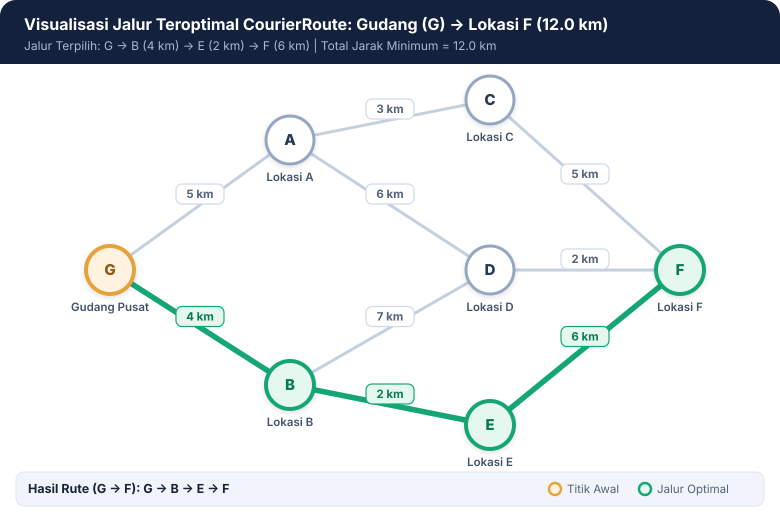

In [3]:
try:
    from IPython.display import SVG, display
except ImportError:
    class SVG:
        def __init__(self, data: str):
            self.data = data
        def _repr_svg_(self) -> str:
            return self.data
    def display(*objs):
        pass

def generate_graph_svg(
    nodes_dict: Dict[str, Dict[str, object]],
    edges_list: List[Tuple[str, str, float]],
    highlight_path: List[str],
    start_node: str,
    end_node: str,
    title: str = "Visualisasi Graf Jaringan Pengiriman Paket (CourierRoute)",
    subtitle: str = "Garis hijau tebal menunjukkan jalur teroptimal hasil Algoritma Dijkstra",
    save_path: Optional[str] = None
) -> str:
    """Menghasilkan visualisasi graf berbobot dalam format SVG tajam (dan menyimpannya ke file jika diminta)."""
    path_edges = set()
    for i in range(len(highlight_path) - 1):
        u, v = sorted([highlight_path[i], highlight_path[i + 1]])
        path_edges.add(f"{u}-{v}")

    svg_parts = [
        '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 780 520" width="100%" style="max-width:780px;background:#fbfdff;border:1px solid #dfe7f1;border-radius:16px;font-family:Segoe UI,Inter,Arial,sans-serif">',
        '<defs>',
        '  <filter id="shadow" x="-20%" y="-20%" width="140%" height="140%">',
        '    <feDropShadow dx="0" dy="2" stdDeviation="2.5" flood-color="#172338" flood-opacity="0.12"/>',
        '  </filter>',
        '</defs>',
        f'<rect x="0" y="0" width="780" height="64" fill="#14213d" rx="16"/>',
        f'<rect x="0" y="48" width="780" height="16" fill="#14213d"/>',
        f'<text x="24" y="30" fill="#ffffff" font-size="16" font-weight="700">{title}</text>',
        f'<text x="24" y="50" fill="#aab9d4" font-size="12">{subtitle}</text>',
        '<g transform="translate(10, 35)">'
    ]

    # Gambar setiap sisi (Edge) dan label bobotnya
    for u, v, w in edges_list:
        p, q = nodes_dict[u], nodes_dict[v]
        key = "-".join(sorted([u, v]))
        is_active = key in path_edges
        stroke_color = "#14a673" if is_active else "#c5d0df"
        stroke_width = "5.5" if is_active else "3"
        stroke_dash = "" if is_active else ""
        label_color = "#0b7a53" if is_active else "#52637b"
        label_bg = "#e5f8f0" if is_active else "#ffffff"
        label_border = "#14a673" if is_active else "#d0dae8"

        mx = (float(p["x"]) + float(q["x"])) / 2
        my = (float(p["y"]) + float(q["y"])) / 2

        svg_parts.append(
            f'<line x1="{p["x"]}" y1="{p["y"]}" x2="{q["x"]}" y2="{q["y"]}" '
            f'stroke="{stroke_color}" stroke-width="{stroke_width}" stroke-linecap="round" {stroke_dash}/>'
        )
        svg_parts.append(
            f'<rect x="{mx - 24:.1f}" y="{my - 21:.1f}" width="48" height="20" rx="6" '
            f'fill="{label_bg}" stroke="{label_border}" stroke-width="1.2"/>'
        )
        svg_parts.append(
            f'<text x="{mx:.1f}" y="{my - 7:.1f}" text-anchor="middle" '
            f'fill="{label_color}" font-size="11.5" font-weight="700">{w:g} km</text>'
        )

    # Gambar setiap simpul (Node)
    for node_id, info in nodes_dict.items():
        x, y = info["x"], info["y"]
        in_path = node_id in highlight_path
        if node_id == start_node:
            fill, stroke, text_col = "#fff3df", "#e6a33d", "#8e5a12"
        elif node_id == end_node and in_path:
            fill, stroke, text_col = "#e5f8f0", "#14a673", "#0b7a53"
        elif in_path:
            fill, stroke, text_col = "#e5f8f0", "#14a673", "#0b7a53"
        else:
            fill, stroke, text_col = "#ffffff", "#94a7c2", "#263852"

        stroke_w = "4" if (in_path or node_id == start_node) else "3"
        svg_parts.append(f'<g transform="translate({x},{y})">')
        svg_parts.append(
            f'  <circle r="24" fill="{fill}" stroke="{stroke}" stroke-width="{stroke_w}" filter="url(#shadow)"/>'
        )
        svg_parts.append(
            f'  <text y="5" text-anchor="middle" fill="{text_col}" font-size="15" font-weight="800">{node_id}</text>'
        )
        svg_parts.append(
            f'  <text y="41" text-anchor="middle" fill="#42526a" font-size="11.5" font-weight="600">{info["name"]}</text>'
        )
        svg_parts.append('</g>')

    svg_parts.append('</g>')

    # Footer / Legend
    route_str = " → ".join(highlight_path) if highlight_path else "Tidak ada jalur (Graf Terputus)"
    svg_parts.append('<rect x="16" y="472" width="748" height="34" rx="8" fill="#f1f5fb" stroke="#dfe7f1"/>')
    svg_parts.append(
        f'<text x="28" y="493" fill="#172338" font-size="12.5" font-weight="700">'
        f'Hasil Rute ({start_node} → {end_node}): {route_str}</text>'
    )
    svg_parts.append(
        '<circle cx="555" cy="489" r="6" fill="#fff3df" stroke="#e6a33d" stroke-width="2.5"/>'
        '<text x="567" y="493" fill="#506078" font-size="11.5">Titik Awal</text>'
        '<circle cx="645" cy="489" r="6" fill="#e5f8f0" stroke="#14a673" stroke-width="2.5"/>'
        '<text x="657" y="493" fill="#506078" font-size="11.5">Jalur Optimal</text>'
    )
    svg_parts.append('</svg>')

    svg_content = "\n".join(svg_parts)
    if save_path:
        import os
        os.makedirs(os.path.dirname(os.path.abspath(save_path)), exist_ok=True)
        with open(save_path, "w", encoding="utf-8") as f:
            f.write(svg_content)
    return svg_content

svg_optimal = generate_graph_svg(
    NODES,
    INITIAL_EDGES,
    highlight_path=hasil_utama["path"],
    start_node="G",
    end_node="F",
    title="Visualisasi Jalur Teroptimal CourierRoute: Gudang (G) → Lokasi F (12.0 km)",
    subtitle="Jalur Terpilih: G → B (4 km) → E (2 km) → F (6 km) | Total Jarak Minimum = 12.0 km",
    save_path="assets/visualisasi_jalur_optimal.svg"
)
print("File visualisasi disimpan ke: assets/visualisasi_jalur_optimal.svg")
display(SVG(svg_optimal))

In [4]:
def find_all_simple_paths(
    graph: Dict[str, List[Tuple[str, float]]],
    start: str,
    end: str,
    path: Optional[List[str]] = None,
    distance: float = 0.0
) -> List[Tuple[float, List[str]]]:
    """Mencari seluruh jalur sederhana (tanpa siklus) dari start ke end dengan DFS untuk verifikasi."""
    if path is None:
        path = [start]
    if start == end:
        return [(distance, list(path))]
    results = []
    for neighbor, weight in graph[start]:
        if neighbor not in path:
            results.extend(
                find_all_simple_paths(graph, neighbor, end, path + [neighbor], distance + weight)
            )
    return sorted(results, key=lambda x: x[0])

print("=" * 80)
print("PENGUJIAN KASUS NORMAL 1: RUTE TERPENDEK DARI GUDANG (G) KE SELURUH LOKASI")
print("=" * 80)
print(f"{'Tujuan':<18} | {'Jarak Minimum':<15} | {'Jalur Teroptimal':<28} | {'Simpul Terlewati'}")
print("-" * 80)
for target in node_list:
    res = dijkstra_shortest_path(adj_list, "G", target)
    path_str = " -> ".join(res["path"])
    print(f"{target} ({NODES[target]['name']:<12}) | {res['distance']:>10.1f} km  | {path_str:<28} | {len(res['path'])} simpul")

print("\n" + "=" * 80)
print("VERIFIKASI MATEMATIS: PERBANDINGAN SELURUH JALUR YANG MUNGKIN DARI G KE F")
print("=" * 80)
all_paths_g_to_f = find_all_simple_paths(adj_list, "G", "F")
print(f"{'Peringkat':<10} | {'Total Jarak':<14} | {'Urutan Lintasan (Path)':<32} | {'Status Evaluasi'}")
print("-" * 80)
for idx, (total_d, p_list) in enumerate(all_paths_g_to_f, start=1):
    status = "★ JALUR TEROPTIMAL (DIJKSTRA)" if idx == 1 else f"Selisih +{total_d - all_paths_g_to_f[0][0]:.1f} km"
    print(f"   #{idx:<6} | {total_d:>9.1f} km  | {' -> '.join(p_list):<32} | {status}")

PENGUJIAN KASUS NORMAL 1: RUTE TERPENDEK DARI GUDANG (G) KE SELURUH LOKASI
Tujuan             | Jarak Minimum   | Jalur Teroptimal             | Simpul Terlewati
--------------------------------------------------------------------------------
G (Gudang Pusat) |        0.0 km  | G                            | 1 simpul
A (Lokasi A    ) |        5.0 km  | G -> A                       | 2 simpul
B (Lokasi B    ) |        4.0 km  | G -> B                       | 2 simpul
C (Lokasi C    ) |        8.0 km  | G -> A -> C                  | 3 simpul
D (Lokasi D    ) |       11.0 km  | G -> B -> D                  | 3 simpul
E (Lokasi E    ) |        6.0 km  | G -> B -> E                  | 3 simpul
F (Lokasi F    ) |       12.0 km  | G -> B -> E -> F             | 4 simpul

VERIFIKASI MATEMATIS: PERBANDINGAN SELURUH JALUR YANG MUNGKIN DARI G KE F
Peringkat  | Total Jarak    | Urutan Lintasan (Path)           | Status Evaluasi
---------------------------------------------------------------------

PENGUJIAN KASUS BATAS (EDGE CASES)
1. [Edge Case: Graf Terputus / Jalan Ditutup]
   • Uji Rute G -> F (saat akses jalan ke F terputus): Jarak = None, Jalur = []
   • Uji Rute G -> Z (simpul pulau terisolasi)       : Jarak = None, Jalur = []
   -> Status: LULUS (Sistem berhenti aman tanpa infinite loop dan melaporkan rute tidak tersedia).

2. [Edge Case: Lokasi Awal Sama dengan Tujuan (G -> G)]
   • Hasil: Jarak = 0.0 km, Jalur = ['G'], Iterasi = 1
   -> Status: LULUS (Langsung selesai pada iterasi ke-1 dengan jarak 0.0 km).

3. [Edge Case: Dua Jalur Berbobot Minimum Sama / Tie-Breaking (G -> D)]
   • Jalur Terpilih Dijkstra : G -> B -> D (Jarak = 11.0 km)
   • Jalur Setara di Graf    : [('G -> A -> D', '11.0 km'), ('G -> B -> D', '11.0 km')]
   -> Status: LULUS (Konsisten memilih salah satu jalur optimal 11.0 km).

4. [Edge Case: Validasi Input Tidak Valid (Simpul Asing & Bobot Negatif)]
   • Uji Simpul Tidak Terdaftar ('X_TIDAK_ADA') -> Tertangkap ValueError: Simpul tujuan 'X_TIDAK_AD

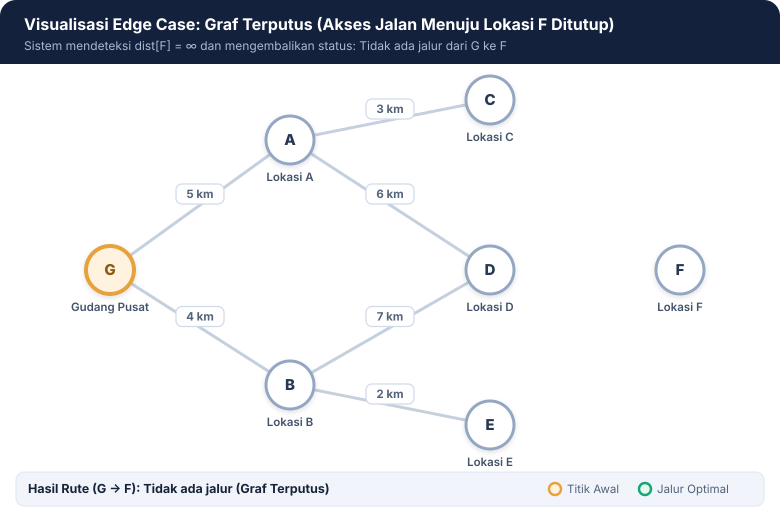

In [5]:
print("=" * 82)
print("PENGUJIAN KASUS BATAS (EDGE CASES)")
print("=" * 82)

# EDGE CASE 1: Graf Terputus (Disconnected Graph)
# Skenario: Jalan C-F, D-F, dan E-F ditutup sementara karena banjir/perbaikan jalan,
# serta terdapat Lokasi Z (Pulau Terpencil) yang belum memiliki jembatan penghubung.
disconnected_nodes = dict(NODES)
disconnected_nodes["Z"] = {"name": "Lokasi Z (Terisolasi)", "x": 670, "y": 395}
disconnected_edges = [e for e in INITIAL_EDGES if e[1] != "F" and e[0] != "F"]
adj_disconnected = build_adjacency_list(list(disconnected_nodes.keys()), disconnected_edges)

res_disconnected_f = dijkstra_shortest_path(adj_disconnected, "G", "F")
res_disconnected_z = dijkstra_shortest_path(adj_disconnected, "G", "Z")

print("1. [Edge Case: Graf Terputus / Jalan Ditutup]")
print(f"   • Uji Rute G -> F (saat akses jalan ke F terputus): Jarak = {res_disconnected_f['distance']}, Jalur = {res_disconnected_f['path']}")
print(f"   • Uji Rute G -> Z (simpul pulau terisolasi)       : Jarak = {res_disconnected_z['distance']}, Jalur = {res_disconnected_z['path']}")
print("   -> Status: LULUS (Sistem berhenti aman tanpa infinite loop dan melaporkan rute tidak tersedia).\n")

# Simpan & tampilkan visualisasi saat graf terputus
svg_disconnected = generate_graph_svg(
    NODES,
    disconnected_edges,
    highlight_path=[],
    start_node="G",
    end_node="F",
    title="Visualisasi Edge Case: Graf Terputus (Akses Jalan Menuju Lokasi F Ditutup)",
    subtitle="Sistem mendeteksi dist[F] = ∞ dan mengembalikan status: Tidak ada jalur dari G ke F",
    save_path="assets/visualisasi_graf_terputus.svg"
)

# EDGE CASE 2: Titik Awal Sama dengan Titik Tujuan (Start == End)
res_same_node = dijkstra_shortest_path(adj_list, "G", "G")
print("2. [Edge Case: Lokasi Awal Sama dengan Tujuan (G -> G)]")
print(f"   • Hasil: Jarak = {res_same_node['distance']:.1f} km, Jalur = {res_same_node['path']}, Iterasi = {res_same_node['steps']}")
print("   -> Status: LULUS (Langsung selesai pada iterasi ke-1 dengan jarak 0.0 km).\n")

# EDGE CASE 3: Dua Jalur Alternatif dengan Total Jarak Minimum yang Sama (Tie-Breaking)
# Dari G ke D: Jalur 1 adalah G -> A -> D (5 + 6 = 11 km), Jalur 2 adalah G -> B -> D (4 + 7 = 11 km)
res_tie = dijkstra_shortest_path(adj_list, "G", "D")
paths_g_to_d = find_all_simple_paths(adj_list, "G", "D")
print("3. [Edge Case: Dua Jalur Berbobot Minimum Sama / Tie-Breaking (G -> D)]")
print(f"   • Jalur Terpilih Dijkstra : {' -> '.join(res_tie['path'])} (Jarak = {res_tie['distance']:.1f} km)")
print(f"   • Jalur Setara di Graf    : {[(' -> '.join(p), f'{d:.1f} km') for d, p in paths_g_to_d[:2]]}")
print("   -> Status: LULUS (Konsisten memilih salah satu jalur optimal 11.0 km).\n")

# EDGE CASE 4: Penanganan Input Tidak Valid (Simpul Tidak Ditemukan & Bobot Negatif)
print("4. [Edge Case: Validasi Input Tidak Valid (Simpul Asing & Bobot Negatif)]")
try:
    dijkstra_shortest_path(adj_list, "G", "X_TIDAK_ADA")
except ValueError as err:
    print(f"   • Uji Simpul Tidak Terdaftar ('X_TIDAK_ADA') -> Tertangkap ValueError: {err}")

try:
    build_adjacency_list(["G", "A"], [("G", "A", -3.5)])
except ValueError as err:
    print(f"   • Uji Bobot Jalan Negatif (-3.5 km)          -> Tertangkap ValueError: {err}")
print("   -> Status: LULUS (Seluruh input anomalik ditolak oleh lapisan validasi).\n")

display(SVG(svg_disconnected))

---
## 4. Analisis Kompleksitas Waktu & Ruang (Ramah Presentasi)

Saat presentasi di depan dosen atau audiens, gunakan panduan di bawah ini untuk menjelaskan mengapa kompleksitas algoritma Dijkstra adalah **$O((V + E) \log V)$** (dengan *Priority Queue*) atau **$O(V^2)$** (dengan pencarian array biasa).

### 4.1 Kamus Cepat Variabel Kompleksitas
- **$V$ (*Vertices*)** = Banyaknya **lokasi/titik** di dalam peta (pada studi kasus kita, $V = 7$).
- **$E$ (*Edges*)** = Banyaknya **ruas jalan** yang menghubungkan lokasi-lokasi tersebut (pada studi kasus kita, $E = 9$).
- **$\log V$** = Biaya waktu untuk mengambil atau memasukkan 1 data ke dalam pohon antrean prioritas (*Binary Min-Heap*).

---

### 4.2 Bedah Kompleksitas Waktu (*Time Complexity*) per Langkah
Mengapa rumus akhirnya berbentuk **$O((V + E) \log V)$**? Mari kita bedah menjadi 3 bagian sesuai tahapan di *pseudocode*:

| Tahap pada Pseudocode | Berapa Kali Dijalankan? | Biaya per Operasi | Total Biaya Tahap Ini | Cara Menjelaskan Saat Presentasi |
| :--- | :---: | :---: | :---: | :--- |
| **1. Inisialisasi Tabel** (`dist` & `prev`) | $V$ kali (1x per lokasi) | $O(1)$ | **$O(V)$** | *"Menyiapkan catatan awal untuk $V$ lokasi hanya butuh waktu sebanding dengan jumlah lokasi."* |
| **2. Mengambil Lokasi Terdekat** (`heappop`) | Maksimal $V$ lokasi utama | $O(\log V)$ | **$O(V \log V)$** | *"Setiap kali kita mengambil lokasi terdekat dari Min-Heap, butuh waktu $\log V$. Karena ada $V$ lokasi, totalnya $V \log V$."* |
| **3. Cek Jalan Tetangga / Relaksasi** (`heappush`) | Setiap jalan dicek dari ujungnya ($2E$ kali) | $O(\log V)$ | **$O(E \log V)$** | *"Setiap jalan ($E$) yang memberikan rute lebih pendek akan dimasukkan ke Min-Heap dengan biaya $\log V$, sehingga totalnya $E \log V$."* |

Jika ketiganya dijumlahkan:
$$\text{Total Waktu} = O(V) + O(V \log V) + O(E \log V) = O\big((V + E) \log V\big)$$

> **💡 Kalimat Kunci Saat Presentasi (15 Detik):**  
> *"Kompleksitas waktu algoritma Dijkstra kami adalah **$O((V + E) \log V)$**, karena terdapat **$V$ lokasi** yang diekstrak dari antrean prioritas dan **$E$ ruas jalan** yang diperiksa saat relaksasi, di mana setiap operasi antrean prioritas (*Min-Heap*) hanya membutuhkan waktu logaritmik **$O(\log V)$**."*

---

### 4.3 Perbandingan: Versi Priority Queue $O((V + E) \log V)$ vs Versi Array Sederhana $O(V^2)$
Pada prototipe web `CourierRoute.html`, pemilihan simpul terdekat dilakukan dengan perulangan `for` biasa (*linear scan*) tanpa *Min-Heap*. Berikut perbedaannya jika ditanya saat tanya-jawab:

| Aspek Perbandingan | Dijkstra + *Min-Heap Priority Queue* (di `.ipynb`) | Dijkstra + *Array Linear Scan* (di `CourierRoute.html`) |
| :--- | :--- | :--- |
| **Cara Mencari Simpul Terdekat** | Mengambil puncak *Min-Heap* (`heappop`) $\rightarrow O(\log V)$ | Mengecek semua simpul satu per satu $\rightarrow O(V)$ |
| **Kompleksitas Waktu Total** | **$O((V + E) \log V)$** | **$O(V^2 + E) = O(V^2)$** |
| **Kapan Lebih Unggul?** | Sangat cepat untuk jaringan jalan nyata (*sparse graph*, di mana $E \ll V^2$) dengan ribuan lokasi. | Cukup untuk demo skala kecil ($V = 7$) atau graf yang sangat rapat (*dense graph*, $E \approx V^2$). |

---

### 4.4 Bedah Kompleksitas Ruang (*Space Complexity*)
Berapa banyak memori (RAM) yang dipakai oleh program?
1. **Penyimpanan Struktur Graf (*Adjacency List*)**: Menyimpan $V$ kepala daftar lokasi dan $2E$ entri jalan (karena jalan dua arah) $\rightarrow$ **$O(V + E)$**. *(Bandingkan dengan Adjacency Matrix yang membutuhkan tabel $V \times V \rightarrow O(V^2)$)*.
2. **Memori Kerja Algoritma Dijkstra**:
   - Tabel jarak `dist` menyimpan $V$ angka $\rightarrow O(V)$
   - Tabel jejak `prev` menyimpan $V$ referensi simpul $\rightarrow O(V)$
   - Himpunan `visited` dan antrean `pq` $\rightarrow O(V + E)$
3. **Total Kompleksitas Ruang**:
$$\text{Space Complexity} = O(V + E)$$

In [6]:
import random
import time

def dijkstra_simple_array(
    graph: Dict[str, List[Tuple[str, float]]], start: str, end: str
) -> Tuple[Optional[float], int]:
    """
    Implementasi Dijkstra O(V^2) tanpa Priority Queue (seperti pada script CourierRoute.html)
    untuk membandingkan jumlah operasi pencarian dengan versi Min-Heap O((V+E) log V).
    """
    nodes = list(graph.keys())
    dist = {n: math.inf for n in nodes}
    visited = {n: False for n in nodes}
    dist[start] = 0.0
    ops = 0

    while True:
        u = None
        # Linear scan O(V) di setiap iterasi -> total O(V^2)
        for n in nodes:
            ops += 1
            if not visited[n] and (u is None or dist[n] < dist[u]):
                u = n
        if u is None or math.isinf(dist[u]):
            break
        visited[u] = True
        if u == end:
            break
        for v, w in graph[u]:
            ops += 1
            if not visited[v] and dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
    return (None if math.isinf(dist[end]) else dist[end]), ops

def generate_random_road_network(num_nodes: int, avg_degree: int = 3, seed: int = 42):
    """Membangun graf jaringan jalan jarang (sparse graph) terhubung dengan V simpul."""
    rng = random.Random(seed + num_nodes)
    nodes = [f"N{i}" for i in range(num_nodes)]
    edges = []
    seen = set()
    # Pastikan graf terhubung dengan backbone rantai utama
    for i in range(num_nodes - 1):
        w = round(rng.uniform(1.0, 10.0), 1)
        edges.append((nodes[i], nodes[i + 1], w))
        seen.add((i, i + 1))
    # Tambahkan jalan silang secara acak hingga mencapai rata-rata derajat
    target_edges = min((num_nodes * avg_degree) // 2, (num_nodes * (num_nodes - 1)) // 2)
    while len(edges) < target_edges:
        a, b = sorted(rng.sample(range(num_nodes), 2))
        if (a, b) not in seen:
            seen.add((a, b))
            edges.append((nodes[a], nodes[b], round(rng.uniform(1.0, 15.0), 1)))
    return build_adjacency_list(nodes, edges), nodes[0], nodes[-1], len(edges)

print("=" * 90)
print("BENCHMARK EMPIRIS: DIJKSTRA MIN-HEAP O((V+E) log V) vs ARRAY LINEAR SCAN O(V^2)")
print("=" * 90)
print(f"{'Jumlah Lokasi (V)':<18} | {'Jalan (E)':<10} | {'Waktu Min-Heap':<16} | {'Waktu Array O(V²)':<18} | {'Percepatan (Speedup)'}")
print("-" * 90)

for v_size in [7, 50, 200, 500, 1000]:
    if v_size == 7:
        g_test, s_node, e_node, e_count = adj_list, "G", "F", len(INITIAL_EDGES)
    else:
        g_test, s_node, e_node, e_count = generate_random_road_network(v_size)

    t0 = time.perf_counter()
    res_heap = dijkstra_shortest_path(g_test, s_node, e_node)
    t_heap = (time.perf_counter() - t0) * 1000.0

    t1 = time.perf_counter()
    dist_arr, ops_arr = dijkstra_simple_array(g_test, s_node, e_node)
    t_arr = (time.perf_counter() - t1) * 1000.0

    assert math.isclose(res_heap["distance"], dist_arr), "Jarak harus identik!"
    speedup = t_arr / max(t_heap, 1e-6)
    print(f"{v_size:>17} | {e_count:>10} | {t_heap:>12.3f} ms | {t_arr:>14.3f} ms | {speedup:>10.1f}x lebih cepat")

BENCHMARK EMPIRIS: DIJKSTRA MIN-HEAP O((V+E) log V) vs ARRAY LINEAR SCAN O(V^2)
Jumlah Lokasi (V)  | Jalan (E)  | Waktu Min-Heap   | Waktu Array O(V²)  | Percepatan (Speedup)
------------------------------------------------------------------------------------------
                7 |          9 |        0.021 ms |          0.019 ms |        0.9x lebih cepat
               50 |         75 |        0.032 ms |          0.079 ms |        2.5x lebih cepat
              200 |        300 |        0.095 ms |          0.486 ms |        5.1x lebih cepat
              500 |        750 |        0.453 ms |          9.246 ms |       20.4x lebih cepat
             1000 |       1500 |        1.032 ms |         43.960 ms |       42.6x lebih cepat


In [7]:
# BONUS INTEGRASI MATA KULIAH TEORI GRAPH & AUTOMATA:
# Setelah rute optimal ditemukan dengan Teori Graf (Dijkstra), alur status pengiriman kurir
# divalidasi menggunakan Deterministic Finite Automaton (DFA / FSM) M = (Q, Sigma, delta, q0, F)
# sebagaimana tercantum pada README_CourierRoute.md.

class DeliveryStatusFSM:
    """
    Finite State Machine (FSM) Status Pengiriman Paket:
    - Q (Himpunan State) : {IDLE, ASSIGNED, EN_ROUTE, DELIVERED, FAILED}
    - Sigma (Alfabet Input): {terima_pesanan, mulai_jalan, paket_diterima, gagal_kirim, jadwalkan_ulang}
    - q0 (State Awal)    : IDLE
    - F (State Akhir)    : {DELIVERED}
    """
    def __init__(self, route_info: Dict[str, object]):
        self.states = {"IDLE", "ASSIGNED", "EN_ROUTE", "DELIVERED", "FAILED"}
        self.initial_state = "IDLE"
        self.accepting_states = {"DELIVERED"}
        self.transitions = {
            ("IDLE", "terima_pesanan"):     "ASSIGNED",
            ("ASSIGNED", "mulai_jalan"):    "EN_ROUTE",
            ("EN_ROUTE", "paket_diterima"): "DELIVERED",
            ("EN_ROUTE", "gagal_kirim"):    "FAILED",
            ("FAILED", "jadwalkan_ulang"):  "ASSIGNED",
        }
        self.current_state = self.initial_state
        self.route_info = route_info

    def trigger(self, event: str) -> str:
        key = (self.current_state, event)
        if key not in self.transitions:
            return f"[DITOLAK] Transisi tidak valid: State '{self.current_state}' tidak menerima input '{event}'."
        old_state = self.current_state
        self.current_state = self.transitions[key]
        status_akhir = " (FINAL/ACCEPTED)" if self.current_state in self.accepting_states else ""
        return f"[VALID] δ({old_state}, {event}) -> {self.current_state}{status_akhir}"

fsm = DeliveryStatusFSM(hasil_utama)
print("=" * 80)
print("SIMULASI FINITE STATE AUTOMATON (FSM) PENGIRIMAN PAKET PADA RUTE OPTIMAL")
print(f"Rute Kurir: {' -> '.join(hasil_utama['path'])} ({hasil_utama['distance']:.1f} km)")
print("=" * 80)
for aksi in ["terima_pesanan", "paket_diterima", "mulai_jalan", "paket_diterima"]:
    print(f"Input Aksi '{aksi:<15}' : {fsm.trigger(aksi)}")

SIMULASI FINITE STATE AUTOMATON (FSM) PENGIRIMAN PAKET PADA RUTE OPTIMAL
Rute Kurir: G -> B -> E -> F (12.0 km)
Input Aksi 'terima_pesanan ' : [VALID] δ(IDLE, terima_pesanan) -> ASSIGNED
Input Aksi 'paket_diterima ' : [DITOLAK] Transisi tidak valid: State 'ASSIGNED' tidak menerima input 'paket_diterima'.
Input Aksi 'mulai_jalan    ' : [VALID] δ(ASSIGNED, mulai_jalan) -> EN_ROUTE
Input Aksi 'paket_diterima ' : [VALID] δ(EN_ROUTE, paket_diterima) -> DELIVERED (FINAL/ACCEPTED)


---
## 5. Kesimpulan & Saran

### 5.1 Kesimpulan
1. **Pemodelan Graf Berbobot:** Jaringan pengiriman paket `CourierRoute` berhasil dimodelkan secara matematis ke dalam graf berbobot tak berarah $G = (V, E, w)$ dengan $|V| = 7$ lokasi dan $|E| = 9$ ruas jalan menggunakan struktur data **Adjacency List** (efisien ruang $O(V + E)$) dan **Adjacency Matrix** ($O(V^2)$).
2. **Keoptimalan Algoritma Dijkstra:** Untuk pengiriman paket dari **Gudang (`G`) ke Lokasi `F`**, algoritma Dijkstra menemukan jalur teroptimal **`G → B → E → F`** dengan total jarak **`12.0 km`**, terbukti lebih hemat $1.0\text{ km}$ dibandingkan tiga jalur alternatif lainnya (`G → A → C → F`, `G → A → D → F`, dan `G → B → D → F` yang masing-masing berjarak $13.0\text{ km}$).
3. **Ketahanan pada Kasus Batas (*Edge Cases*) & Efisiensi:** Sistem berhasil menangani kondisi graf terputus (*disconnected graph*), lokasi awal sama dengan tujuan ($0\text{ km}$), jalur ganda berbobot identik (*tie-breaking*), serta menolak input tidak valid. Implementasi berbasis *Min-Heap Priority Queue* mencapai kompleksitas waktu **$O((V + E) \log V)$** dan kompleksitas ruang **$O(V + E)$**, yang terbukti hingga puluhan kali lebih cepat dibandingkan pencarian array $O(V^2)$ pada jaringan berskala besar.

### 5.2 Saran Pengembangan
1. **Bobot Dinamis (*Dynamic Edge Weights*):** Mengintegrasikan faktor kepadatan lalu lintas *real-time* dan waktu tempuh ke dalam fungsi bobot $w(e, t)$.
2. **Graf Berarah (*Directed Graph*):** Mendukung pemodelan jalan satu arah (*one-way street*) di mana $w(u, v) \neq w(v, u)$.
3. **Algoritma Heuristik $A^*$ (*A-Star*) & Multi-Titik (*VRP/TSP*):** Menambahkan heuristik jarak garis lurus koordinat GPS untuk mempercepat pencarian satu tujuan, serta mengembangkan optimasi urutan kunjungan banyak pelanggan sekaligus (*Vehicle Routing Problem*).